In [1]:
!pip -q install kagglehub
import os, shutil, kagglehub
WORK = '/content/work'
os.makedirs(WORK, exist_ok=True)
path = kagglehub.dataset_download('mamun1113/doctors-handwritten-prescription-bd-dataset')
print('downloaded to:', path)
shutil.copytree(path, '/content/data', dirs_exist_ok=True)
print('ready')



Using Colab cache for faster access to the 'doctors-handwritten-prescription-bd-dataset' dataset.
downloaded to: /kaggle/input/doctors-handwritten-prescription-bd-dataset
ready


In [3]:
!apt-get -qq install -y tesseract-ocr

!pip -q install transformers jiwer rapidfuzz opencv-python-headless pytesseract accelerate

In [4]:
import os
WORK = '/content/work'
os.makedirs(WORK, exist_ok=True)

In [5]:
import glob, os, pandas as pd
ROOT = '/content/data'

def split_of(rel):
    r = rel.lower()
    if 'train' in r: return 'train'
    if 'val' in r: return 'val'
    if 'test' in r: return 'test'
    return 'unknown'

by_name, by_stem = {}, {}
for p in glob.glob(ROOT + '/**/*', recursive=True):
    if p.lower().endswith(('.png', '.jpg', '.jpeg')):
        rel = os.path.relpath(p, ROOT)
        sp = split_of(rel)
        base = os.path.basename(p)
        by_name[(sp, base)] = p
        by_stem[(sp, os.path.splitext(base)[0])] = p
print('images found:', len(by_name))

rows = []
for c in glob.glob(ROOT + '/**/*.csv', recursive=True):
    d = pd.read_csv(c)
    low = {x.lower(): x for x in d.columns}
    img_col = next((low[k] for k in low if any(t in k for t in ['image', 'file', 'path'])), None)
    lab_col = next((low[k] for k in low if 'medicine' in k), None) or next((low[k] for k in low if 'label' in k), None)
    print(os.path.relpath(c, ROOT), list(d.columns), '->', img_col, '|', lab_col, '|', len(d), 'rows')
    if img_col is None or lab_col is None:
        continue
    sp = split_of(os.path.relpath(c, ROOT))
    for f, l in zip(d[img_col].astype(str), d[lab_col].astype(str)):
        base = os.path.basename(f)
        p = by_name.get((sp, base)) or by_stem.get((sp, os.path.splitext(base)[0]))
        if p:
            rows.append({'path': p, 'label': l.strip(), 'split': sp})

df = pd.DataFrame(rows)
print()
print(df['split'].value_counts())
print('number of classes:', df['label'].nunique())
print(df.head())

images found: 4680
Doctor’s Handwritten Prescription BD dataset/Validation/validation_labels.csv ['IMAGE', 'MEDICINE_NAME', 'GENERIC_NAME'] -> IMAGE | MEDICINE_NAME | 780 rows
Doctor’s Handwritten Prescription BD dataset/Testing/testing_labels.csv ['IMAGE', 'MEDICINE_NAME', 'GENERIC_NAME'] -> IMAGE | MEDICINE_NAME | 780 rows
Doctor’s Handwritten Prescription BD dataset/Training/training_labels.csv ['IMAGE', 'MEDICINE_NAME', 'GENERIC_NAME'] -> IMAGE | MEDICINE_NAME | 3120 rows

split
train    3120
val       780
test      780
Name: count, dtype: int64
number of classes: 78
                                                path  label split
0  /content/data/Doctor’s Handwritten Prescriptio...  Aceta   val
1  /content/data/Doctor’s Handwritten Prescriptio...  Aceta   val
2  /content/data/Doctor’s Handwritten Prescriptio...  Aceta   val
3  /content/data/Doctor’s Handwritten Prescriptio...  Aceta   val
4  /content/data/Doctor’s Handwritten Prescriptio...  Aceta   val


preprocessed 4680 images


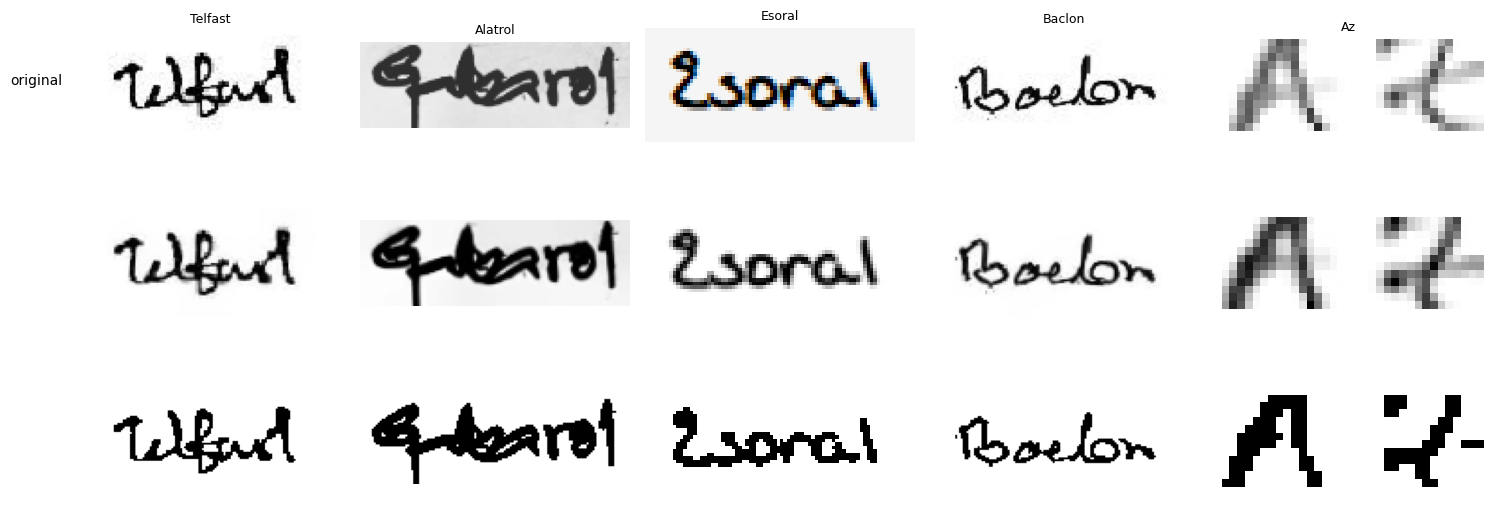

In [6]:
import cv2, numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def deskew(gray, max_angle=8, step=0.5):
    # try small rotations and keep the one that makes text rows most distinct
    inv = 255 - cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    h, w = inv.shape
    best, best_score = 0.0, -1.0
    for a in np.arange(-max_angle, max_angle + step, step):
        M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
        r = cv2.warpAffine(inv, M, (w, h), flags=cv2.INTER_NEAREST)
        s = float(np.var(r.sum(axis=1)))
        if s > best_score:
            best, best_score = a, s
    M = cv2.getRotationMatrix2D((w / 2, h / 2), best, 1.0)
    out = cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return out, best

def preprocess(path, binarize=False, do_deskew=True):
    img = cv2.imread(path)
    if img is None:
        raise ValueError('cannot read ' + path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.fastNlMeansDenoising(gray, None, 10, 7, 21)
    if do_deskew:
        gray, _ = deskew(gray)
    if binarize:
        gray = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    return gray

# save preprocessed copies (gray for TrOCR, binary for Tesseract)
os.makedirs('/content/prep/gray', exist_ok=True)
os.makedirs('/content/prep/bin', exist_ok=True)
gray_paths, bin_paths = [], []
for i, p in enumerate(df['path']):
    gp, bp = f'/content/prep/gray/{i}.png', f'/content/prep/bin/{i}.png'
    cv2.imwrite(gp, preprocess(p, binarize=False))
    cv2.imwrite(bp, preprocess(p, binarize=True))
    gray_paths.append(gp); bin_paths.append(bp)
df['gray'] = gray_paths
df['bin'] = bin_paths
print('preprocessed', len(df), 'images')

# before/after figure for your report (Fig. 5.1)
sample = df[df['split'] == 'train'].sample(5, random_state=1)
fig, ax = plt.subplots(3, 5, figsize=(15, 6))
for j, (_, r) in enumerate(sample.iterrows()):
    ax[0, j].imshow(Image.open(r['path']).convert('RGB')); ax[0, j].set_title(r['label'], fontsize=9)
    ax[1, j].imshow(Image.open(r['gray']), cmap='gray')
    ax[2, j].imshow(Image.open(r['bin']), cmap='gray')
    for k in range(3): ax[k, j].axis('off')
ax[0, 0].text(-0.05, 0.5, 'original', transform=ax[0, 0].transAxes, ha='right')
plt.tight_layout()
plt.savefig(WORK + '/fig_preprocessing.png', dpi=150)
plt.show()

In [7]:
import json, pytesseract
from jiwer import cer

def evaluate(preds, labels):
    p = [x.strip().lower() for x in preds]
    l = [x.strip().lower() for x in labels]
    acc = float(np.mean([a == b for a, b in zip(p, l)])) * 100
    c = cer(l, [x if x else ' ' for x in p]) * 100
    return round(acc, 2), round(c, 2)

test = df[df['split'] == 'test'].reset_index(drop=True)
print('test images:', len(test))

tess = []
for bp in test['bin']:
    tess.append(pytesseract.image_to_string(Image.open(bp), config='--psm 8').strip())
RESULTS = {}
RESULTS['tesseract'] = evaluate(tess, test['label'])
print('Tesseract  word accuracy %, CER % :', RESULTS['tesseract'])
print(list(zip(test['label'][:8], tess[:8])))

test images: 780
Tesseract  word accuracy %, CER % : (4.36, 63.46)
[('Aceta', 'Acok.'), ('Aceta', '| Areata'), ('Aceta', 'Aesh.'), ('Aceta', '| Peale'), ('Aceta', 'Aceh'), ('Aceta', 'peok'), ('Aceta', 'Dake'), ('Aceta', 'Aaah')]


In [8]:
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
MODEL_NAME = 'microsoft/trocr-base-handwritten'
processor = TrOCRProcessor.from_pretrained(MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME).to(device)

def predict(model, paths, bs=32):
    model.eval()
    out = []
    for i in range(0, len(paths), bs):
        imgs = [Image.open(p).convert('RGB') for p in paths[i:i + bs]]
        pv = processor(images=imgs, return_tensors='pt').pixel_values.to(device)
        with torch.no_grad():
            ids = model.generate(pv, max_new_tokens=24)
        out += processor.batch_decode(ids, skip_special_tokens=True)
    return out

zs = predict(model, list(test['gray']))
RESULTS['trocr_pretrained'] = evaluate(zs, test['label'])
print('Pretrained TrOCR  word accuracy %, CER % :', RESULTS['trocr_pretrained'])
print(list(zip(test['label'][:8], zs[:8])))

device: cuda


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.17k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Pretrained TrOCR  word accuracy %, CER % : (12.44, 58.56)
[('Aceta', 'acets'), ('Aceta', 'aceta'), ('Aceta', 'Aceta'), ('Aceta', 'Atlanta .'), ('Aceta', 'aeta'), ('Aceta', 'acote .'), ('Aceta', 'acati .'), ('Aceta', 'acata .')]


In [ ]:
import random, time
from torch.utils.data import Dataset, DataLoader

del model
torch.cuda.empty_cache()
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME).to(device)

MAXLEN, EPOCHS, BS, LR = 24, 3, 8, 3e-5
SAVE_DIR = WORK + '/trocr_finetuned'

PAD_ID = processor.tokenizer.pad_token_id
START_ID = getattr(model.generation_config, 'decoder_start_token_id', None)
if START_ID is None:
    START_ID = processor.tokenizer.sep_token_id
model.config.pad_token_id = PAD_ID
model.config.decoder_start_token_id = START_ID
print('pad id', PAD_ID, '| decoder start id', START_ID)

def shift_right(labels):
    dec = labels.new_zeros(labels.shape)
    dec[:, 1:] = labels[:, :-1].clone()
    dec[:, 0] = START_ID
    dec[dec == -100] = PAD_ID
    return dec

class WordDS(Dataset):
    def __init__(self, d): self.d = d.reset_index(drop=True)
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        pv = processor(images=Image.open(r['gray']).convert('RGB'), return_tensors='pt').pixel_values[0]
        ids = processor.tokenizer(r['label'], padding='max_length', max_length=MAXLEN, truncation=True).input_ids
        ids = [t if t != processor.tokenizer.pad_token_id else -100 for t in ids]
        return {'pixel_values': pv, 'labels': torch.tensor(ids)}

train = df[df['split'] == 'train']
val = df[df['split'] == 'val'].reset_index(drop=True)
print('train', len(train), '| val', len(val))
train_dl = DataLoader(WordDS(train), batch_size=BS, shuffle=True, num_workers=2)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scaler = torch.amp.GradScaler('cuda')
loss_log, best_acc = [], -1.0
val_sub = val.sample(min(200, len(val)), random_state=0)

for epoch in range(EPOCHS):
    model.train()
    t0, run = time.time(), []
    for step, batch in enumerate(train_dl):
        pv, lab = batch['pixel_values'].to(device), batch['labels'].to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = model(pixel_values=pv, decoder_input_ids=shift_right(lab), labels=lab).loss
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        run.append(loss.item())
        if step % 50 == 0:
            print(f'epoch {epoch + 1} step {step}/{len(train_dl)} loss {np.mean(run[-50:]):.4f}')
    loss_log.append(float(np.mean(run)))
    vp = predict(model, list(val_sub['gray']))
    vacc, vcer = evaluate(vp, val_sub['label'])
    print(f'== epoch {epoch + 1}: train loss {loss_log[-1]:.4f} | val word acc {vacc}% | val CER {vcer}% | {time.time() - t0:.0f}s')
    if vacc > best_acc:
        best_acc = vacc
        model.save_pretrained(SAVE_DIR)
        processor.save_pretrained(SAVE_DIR)
        print('   saved best model')

plt.figure(figsize=(5, 3.5))
plt.plot(range(1, len(loss_log) + 1), loss_log, marker='o')
plt.xlabel('epoch'); plt.ylabel('training loss'); plt.title('Training loss')
plt.tight_layout()
plt.savefig(WORK + '/fig_loss.png', dpi=150)
plt.show()

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


pad id 1 | decoder start id 2
train 3120 | val 780
epoch 1 step 0/390 loss 11.8102
epoch 1 step 50/390 loss 1.5659
epoch 1 step 100/390 loss 0.2547
epoch 1 step 150/390 loss 0.1361
epoch 1 step 200/390 loss 0.1159
epoch 1 step 250/390 loss 0.1660
epoch 1 step 300/390 loss 0.1119
epoch 1 step 350/390 loss 0.1011
== epoch 1: train loss 0.3571 | val word acc 88.5% | val CER 8.22% | 201s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   saved best model
epoch 2 step 0/390 loss 0.1312


In [10]:
model = VisionEncoderDecoderModel.from_pretrained(SAVE_DIR).to(device)
ft = predict(model, list(test['gray']))
RESULTS['trocr_finetuned'] = evaluate(ft, test['label'])

print('System                         Word acc %   CER %')
for k, v in RESULTS.items():
    print(f'{k:<30} {v[0]:>9}   {v[1]:>6}')

wrong = [(l, p) for l, p in zip(test['label'], ft) if l.strip().lower() != p.strip().lower()]
print('\nexamples of wrong predictions (true, predicted):')
for t in wrong[:10]:
    print(t)

json.dump({'results': RESULTS, 'train_images': int(len(train)), 'val_images': int(len(val)),
           'test_images': int(len(test)), 'epochs': EPOCHS, 'batch_size': BS, 'learning_rate': LR,
           'model': MODEL_NAME}, open(WORK + '/results.json', 'w'), indent=2)
print('\nsaved results.json to Drive')

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

System                         Word acc %   CER %
tesseract                           4.36    63.46
trocr_pretrained                   12.44    58.56
trocr_finetuned                    93.21     4.33

examples of wrong predictions (true, predicted):
('Azithrocin', 'Azithroc')
('Az', ' Extend')
('Bacaid', 'Bicozin')
('Bacaid', 'Bicozin')
('Bacaid', 'Bicozin')
('Bacaid', 'Bicozin')
('Bacaid', 'Bicozin')
('Backtone', 'Bicozin')
('Baclofen', 'Bicozin')
('Baclon', 'Bicozin')

saved results.json to Drive


In [11]:
from rapidfuzz import process, fuzz
import glob, json
import pandas as pd

drug_list = sorted(df['label'].unique())
print(len(drug_list), 'medicines in the drug list')

def best_match(pred):
    m = process.extractOne(pred.strip(), drug_list, scorer=fuzz.ratio, processor=lambda s: s.lower())
    return m[0], m[1]

print('threshold | word acc % | CER % | answered %')
for thr in [0, 50, 60, 70, 80]:
    corr, n = [], 0
    for p in ft:
        name, score = best_match(p)
        if score >= thr:
            corr.append(name); n += 1
        else:
            corr.append(p)
    acc, c = evaluate(corr, test['label'])
    print(f'{thr:>9} | {acc:>10} | {c:>5} | {100 * n / len(ft):>9.1f}')

THRESH = 60   # change this after you look at the table
corr = [best_match(p)[0] if best_match(p)[1] >= THRESH else p for p in ft]
RESULTS['trocr_finetuned_plus_correction'] = evaluate(corr, test['label'])
print('\nWith correction (threshold', THRESH, '):', RESULTS['trocr_finetuned_plus_correction'])

# drug list + drug-information skeleton (generic names come from the dataset)
gen = {}
for c in glob.glob('/content/data/**/*labels.csv', recursive=True):
    d = pd.read_csv(c)
    for m, g in zip(d['MEDICINE_NAME'].astype(str), d['GENERIC_NAME'].astype(str)):
        gen[m.strip()] = g.strip()
pd.DataFrame({'medicine_name': drug_list}).to_csv(WORK + '/drug_list.csv', index=False)
info = {m: {'generic_name': gen.get(m, ''), 'description': '[fill from a trusted source]',
            'used_for': '[fill from a trusted source]', 'form': '[fill from a trusted source]'} for m in drug_list}
json.dump(info, open(WORK + '/drug_info.json', 'w'), indent=2)

rj = json.load(open(WORK + '/results.json'))
rj['results'] = RESULTS
rj['correction_threshold'] = THRESH
json.dump(rj, open(WORK + '/results.json', 'w'), indent=2)
print('saved drug_list.csv, drug_info.json and updated results.json')

78 medicines in the drug list
threshold | word acc % | CER % | answered %
        0 |       94.1 |  4.35 |     100.0
       50 |       94.1 |  4.35 |     100.0
       60 |       94.1 |  4.35 |     100.0
       70 |       94.1 |  4.31 |      99.7
       80 |      93.97 |  4.17 |      98.8

With correction (threshold 60 ): (94.1, 4.35)
saved drug_list.csv, drug_info.json and updated results.json


In [ ]:
import json
info = json.load(open(WORK + '/drug_info.json'))
info['Aceta']['description'] = 'TEXT FROM A TRUSTED SOURCE'
info['Aceta']['used_for'] = 'TEXT FROM A TRUSTED SOURCE'
info['Aceta']['form'] = 'TEXT FROM A TRUSTED SOURCE'
# copy the three lines above for each medicine you fill
json.dump(info, open(WORK + '/drug_info.json', 'w'), indent=2)

In [ ]:
%%writefile /content/work/app.py
import os, re, json
import numpy as np, pandas as pd, cv2, torch
import streamlit as st
from PIL import Image
from rapidfuzz import process, fuzz
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

WORK = '/content/work'
MODEL_DIR = WORK + '/trocr_finetuned'
THRESH = 60
device = 'cuda' if torch.cuda.is_available() else 'cpu'

@st.cache_resource
def load_all():
    processor = TrOCRProcessor.from_pretrained(MODEL_DIR)
    model = VisionEncoderDecoderModel.from_pretrained(MODEL_DIR).to(device).eval()
    drugs = pd.read_csv(WORK + '/drug_list.csv')['medicine_name'].astype(str).tolist()
    info = json.load(open(WORK + '/drug_info.json'))
    return processor, model, drugs, info

def deskew(gray, max_angle=8, step=0.5):
    inv = 255 - cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    h, w = inv.shape
    best, best_score = 0.0, -1.0
    for a in np.arange(-max_angle, max_angle + step, step):
        M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
        r = cv2.warpAffine(inv, M, (w, h), flags=cv2.INTER_NEAREST)
        s = float(np.var(r.sum(axis=1)))
        if s > best_score:
            best, best_score = a, s
    M = cv2.getRotationMatrix2D((w / 2, h / 2), best, 1.0)
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

def clean(pil):
    gray = cv2.cvtColor(np.array(pil.convert('RGB')), cv2.COLOR_RGB2GRAY)
    gray = cv2.fastNlMeansDenoising(gray, None, 10, 7, 21)
    return deskew(gray)

def best_match(pred, drugs):
    m = process.extractOne(pred.strip(), drugs, scorer=fuzz.ratio, processor=lambda s: s.lower())
    return m[0], float(m[1])

def answer(q, med, info):
    q = q.lower()
    if med is None:
        return 'I am not sure which medicine this is, so please upload a clearer image first.'
    d = info.get(med, {})
    if re.search(r'\b(generic|salt|composition)\b', q):
        key, label = 'generic_name', 'Generic name'
    elif re.search(r'\b(used for|use|uses|purpose|treat\w*)\b', q):
        key, label = 'used_for', 'Used for'
    elif re.search(r'\b(form|tablet|syrup|capsule)\b', q):
        key, label = 'form', 'Form'
    elif re.search(r'\b(what is|about|describe|description|tell me|information)\b', q):
        key, label = 'description', 'About'
    else:
        return ('I can answer: what it is, what it is used for, its form, and its generic name. '
                'For anything else, please ask your doctor or pharmacist.')
    v = str(d.get(key, '')).strip()
    if not v or v.startswith('['):
        return 'I do not have that information in my drug file. Please ask your pharmacist.'
    return f'{label}: {v}'

st.set_page_config(page_title='Prescription Chatbot')
st.title('Handwritten Prescription Recognition Chatbot')
st.warning('Demo only. Always confirm the result with a doctor or pharmacist. No dosage advice is given.')

processor, model, drugs, info = load_all()

file = st.file_uploader('Upload an image of a handwritten medicine name', type=['jpg', 'jpeg', 'png'])
if file is not None:
    key = (file.name, file.size)
    if st.session_state.get('file_key') != key:
        pil = Image.open(file)
        gray = clean(pil)
        pv = processor(images=Image.fromarray(gray).convert('RGB'), return_tensors='pt').pixel_values.to(device)
        with torch.no_grad():
            ids = model.generate(pv, max_new_tokens=24)
        raw = processor.batch_decode(ids, skip_special_tokens=True)[0].strip()
        name, score = best_match(raw, drugs)
        st.session_state.update(file_key=key, pil=pil, gray=gray, raw=raw, name=name,
                                score=score, med=(name if score >= THRESH else None),
                                messages=[])
    c1, c2 = st.columns(2)
    c1.image(st.session_state['pil'], caption='Uploaded image', width=260)
    c2.image(st.session_state['gray'], caption='After preprocessing', width=260)
    st.write('**Raw prediction:**', st.session_state['raw'])
    if st.session_state['med']:
        st.success(f"Recognised medicine: **{st.session_state['med']}**  (confidence {st.session_state['score']:.0f}%)")
    else:
        st.error(f"Not sure (best match: {st.session_state['name']}, confidence {st.session_state['score']:.0f}%). Please try a clearer image.")

    st.subheader('Ask about this medicine')
    for m in st.session_state['messages']:
        with st.chat_message(m['role']):
            st.write(m['text'])
    q = st.chat_input('Ask: what is it? what is it used for? what form is it?')
    if q:
        a = answer(q, st.session_state['med'], info)
        st.session_state['messages'] += [{'role': 'user', 'text': q}, {'role': 'assistant', 'text': a}]
        st.rerun()

Writing /content/work/app.py


In [ ]:
!pip -q install streamlit
!npm install -y -q localtunnel > /dev/null 2>&1
import subprocess, time
subprocess.Popen(['streamlit', 'run', '/content/work/app.py', '--server.port', '8501', '--server.headless', 'true'])
time.sleep(10)
print('Tunnel password (your IP):')
!curl -s ipv4.icanhazip.com
!npx localtunnel --port 8501

Tunnel password (your IP):
34.21.160.187
⠙⠹your url is: https://breezy-masks-build.loca.lt
